# CHAZ forcing

Besides the genesis index (see the genesis-index notebook), CHAZ reads for each year:

| file | what | used by |
| --- | --- | --- |
| `I_MLR_{year}` | monthly 250 and 850 hPa winds, relative humidity averaged over 500, 700 and 850 hPa, PI | track steering, intensity predictors |
| `Cov_{year}_2deg` | per month, the covariance of daily 250/850 hPa wind anomalies from the monthly means | synthetic sub-monthly winds |
| `A_{year}{month}` | its Cholesky factor, interpolated to each day | synthetic sub-monthly winds |
| `PI_{year}` | potential intensity | intensity predictors |

`ocr.risks.hurricane.forcing` ports the CHAZ pre-processing tutorial (Tutorial_chaz_pre.ipynb)
to build these from ERA5. The tutorial data (Zenodo 11631930) include the authors' files for
2017; we compare ours with them.

## Decisions

| | choice | evidence |
| --- | --- | --- |
| daily winds | mean of the 00, 06, 12 and 18 UTC analyses | §1 |
| covariance | the tutorial's: anomalies from monthly means interpolated to each day, per month | §2 |
| Cholesky factor | lower triangle of each day's covariance | §3; the tutorial's notebook code as written transposes it |
| PI | 0 wherever the 2° cell's bilinear footprint touches land or missing SST | §3 |
| grid | 2°, cell centres on odd latitudes; ERA5 sampled at its nodes there | as for TCGI |

In [1]:
import calendar

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import LinearSegmentedColormap

from ocr.risks.hurricane import chaz, forcing, store

OURS, THEIRS, OTHER = '#2a78d6', '#eb6834', '#1baf7a'
SEQ = LinearSegmentedColormap.from_list(
    'blue', ['#cde2fb', '#6da7ec', '#2a78d6', '#184f95', '#0d366b']
)
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)


def ours(name):
    return xr.open_dataset(store.path(f'{store.FORCING}/2017/{name}'))


def theirs(name):
    return xr.open_dataset(store.path(f'{store.TUTORIAL}/{name}'), decode_times=False)


def stats(o, t):
    o, t = np.asarray(o, float).ravel(), np.asarray(t, float).ravel()
    m = np.isfinite(o) & np.isfinite(t)
    d = o[m] - t[m]
    return {
        'rms': np.sqrt((d**2).mean()),
        'rms / sd of theirs': np.sqrt((d**2).mean()) / t[m].std(),
        'max |diff|': np.abs(d).max(),
        'r': np.corrcoef(o[m], t[m])[0, 1],
    }

## 1. Daily winds

The tutorial's daily 250/850 hPa winds are stamped 00 UTC. We fetch January 2017 hourly and
compare three candidates with theirs: the mean of all 24 hours, the mean of the four 6-hourly
analyses, and 00 UTC alone.

In [2]:
daily = theirs('u_v_850_250_2deg_2017_daily.nc').sel(time=slice(0, 30))
hourly = store.open_era5(store.path('validation/forcing/uv_201701_1h_2deg.nc')).sortby('lat')
hourly = hourly.sel(lat=daily.lat.astype(float), lon=daily.lon.astype(float))
candidates = {
    'mean of 24 hours': hourly.resample(time='1D').mean(),
    'mean of 00/06/12/18 UTC (used)': hourly.sel(time=hourly.time.dt.hour % 6 == 0)
    .resample(time='1D')
    .mean(),
    '00 UTC only': hourly.sel(time=hourly.time.dt.hour == 0),
}
rows = {}
for name, c in candidates.items():
    rows[name] = {
        f'{v}{lev}': stats(c[v].sel(level=lev).values, daily[f'{v}{lev}'].values)['rms']
        for v in ('u', 'v')
        for lev in (850, 250)
    }
pd.DataFrame(rows).T.style.format('{:.4f}').set_caption(
    "rms against the tutorial's daily winds, January 2017, m s⁻¹"
)

,u850,u250,v850,v250
mean of 24 hours,0.6908,1.2995,0.7740,1.5708
mean of 00/06/12/18 UTC (used),0.0004,0.0004,0.0004,0.0004
00 UTC only,2.9792,5.5250,3.3682,6.7538


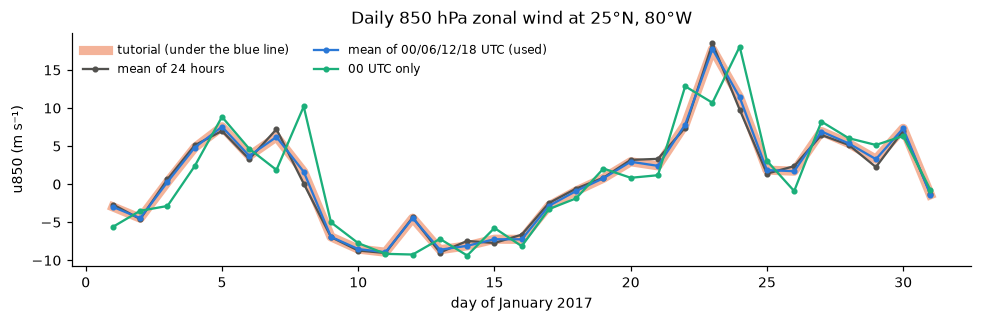

In [3]:
lat, lon = 25.0, 280.0  # off Florida
fig, ax = plt.subplots(figsize=(9, 3))
days = np.arange(1, 32)
ax.plot(
    days,
    daily['u850'].sel(lat=int(lat), lon=int(lon)),
    color=THEIRS,
    lw=6,
    alpha=0.5,
    label='tutorial (under the blue line)',
    zorder=1,
)
for (name, c), color in zip(candidates.items(), ('#52514e', OURS, OTHER)):
    ax.plot(
        days,
        c['u'].sel(level=850, lat=lat, lon=lon),
        color=color,
        lw=1.5,
        marker='o',
        ms=3,
        label=name,
    )
ax.set(
    xlabel='day of January 2017',
    ylabel='u850 (m s⁻¹)',
    title=f'Daily 850 hPa zonal wind at {lat:.0f}°N, {360 - lon:.0f}°W',
)
ax.legend(frameon=False, ncol=2, fontsize=8)
fig.tight_layout()

## 2. Every forcing file

Our 2017 forcing against the tutorial's, field by field, over the whole grid. A rms that is a
small fraction of the field's spread and r of 1 mean close agreement; the largest difference
against the rms says whether what is left is rounding.

In [4]:
rows = []
a, b = ours('I_MLR_2017.nc'), theirs('I_MLR_2017.nc')
for v in ('u850', 'u250', 'v850', 'v250', 'hur', 'PI'):
    rows.append({'file': 'I_MLR', 'field': v, **stats(a[v].values, b[v].values)})
a, b = ours('Cov_2017_2deg.nc'), theirs('Cov_2017_2deg.nc')
for v in forcing.COV_PAIRS:
    rows.append({'file': 'Cov', 'field': v, **stats(a[v].values, b[v].values)})
for m in range(1, 13):
    a, b = ours(f'A_2017{m:02d}.nc'), theirs(f'A_2017{m:02d}.nc')
    rows.append(
        {'file': 'A', 'field': calendar.month_abbr[m], **stats(a['A'].values, b['A'].values)}
    )
(
    pd.DataFrame(rows)
    .set_index(['file', 'field'])
    .style.format(
        {'rms': '{:.2e}', 'rms / sd of theirs': '{:.5f}', 'max |diff|': '{:.2e}', 'r': '{:.6f}'}
    )
)

The winds differ by rounding only. The largest u difference is 7.71e-4 m s⁻¹ against an rms of
4.44e-4, and for v 4.06e-4 against 2.35e-4: in both the largest is √3 times the rms, as for errors
spread evenly over a rounding step twice the largest (about 1.5e-3 m s⁻¹ for u, 8e-4 for v). Our
reading is that the tutorial's ERA5 came as packed 16-bit netCDF, whose step is of that size. The
humidity, covariances and Cholesky factors agree as closely, with rms at most 0.01% of each
field's spread. PI differs at the edge of the land mask; section 3 shows why.

## 3. Two places the tutorial's code and files disagree

**The Cholesky factor.** CHAZ builds sub-monthly winds as A·ε, with A a factor of the daily
covariance and ε white noise. The tutorial's notebook takes `cholesky(cov.T).T`, which
transposes the lower factor and leaves the off-diagonal entries CHAZ reads at zero; its
published A files hold the lower factor. We write the lower factor, which matches the files.
Which of the two the published ERA5 track run used is a question for the tracks notebook.

In [5]:
import datetime

# the tutorial's cell 14 as written, for 15 August 2017, from our covariance (which matches theirs)
cov = ours('Cov_2017_2deg.nc')
c = {v: cov[v].values.copy() for v in forcing.COV_PAIRS}
for v in c:
    c[v][:, 0, :], c[v][:, -1, :] = c[v][:, 1, :], c[v][:, -2, :]
day = datetime.datetime(2017, 8, 15)
stack = np.stack([chaz.date_interpolation(day, c[v]) for v in forcing.COV_PAIRS])  # (10, lat, lon)
covv = np.zeros((4, 4) + stack.shape[1:])
covv[0, :], covv[1, 1:], covv[2, 2:], covv[3, 3] = stack[:4], stack[4:7], stack[7:9], stack[9]
A = np.zeros_like(covv)
bad = np.isnan(covv).any(axis=(0, 1))
A[:, :, ~bad] = np.linalg.cholesky(covv[:, :, ~bad].T).T
pairs = [(0, 0), (1, 0), (1, 1), (2, 0), (2, 1), (2, 2), (3, 0), (3, 1), (3, 2), (3, 3)]
as_written = np.stack([A[i, j] for i, j in pairs])

a = ours('A_201708.nc')['A'].values[:, 14]
b = theirs('A_201708.nc')['A'].values[:, 14]
rows = [
    {
        'entry': f'({i},{j})',
        'ours, rms vs files': stats(a[k], b[k])['rms'],
        'tutorial code as written, rms vs files': stats(as_written[k], b[k])['rms'],
        'files, rms of entry': np.sqrt(np.nanmean(b[k] ** 2)),
    }
    for k, (i, j) in enumerate(pairs)
]
pd.DataFrame(rows).set_index('entry').style.format('{:.3g}').set_caption('A, 15 August 2017, m s⁻¹')

/Users/shaneloeffler/dev/carbonplan/ocr-multi-hazard-tc/.pixi/envs/hurricane/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/shaneloeffler/dev/carbonplan/ocr-multi-hazard-tc/.pixi/envs/hurricane/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,"ours, rms vs files","tutorial code as written, rms vs files","files, rms of entry"
entry,,,
"(0,0)",7.64e-05,7.64e-05,10.8
"(1,0)",0.000105,3.5,3.5
"(1,1)",7.33e-05,7.33e-05,10.9
"(2,0)",8.48e-05,2.91,2.91
"(2,1)",8.56e-05,1.15,1.15
"(2,2)",7.53e-05,7.53e-05,4.01
"(3,0)",7.84e-05,1.33,1.33
"(3,1)",7.79e-05,2.89,2.89
"(3,2)",0.000102,1.19,1.19


**PI at the land edge.** PI from tcpyPI is defined wherever ERA5 has SST. The tutorial's files
set PI to 0 wherever the cell's bilinear footprint on the 0.25° grid touches missing SST, the
same rule as TCGI's ocean mask, so we apply that mask to PI too.

In [6]:
unmasked = xr.open_dataset(store.path(f'{store.VALIDATION}/compare_2017.nc'))['PI_ours'].values
masked = ours('PI_2017.nc')['vmax'].values
files = theirs('PI_2017.nc')['vmax'].values
edge = (unmasked > 0) & (files == 0)
rows = {}
for name, pi in (('PI as computed', unmasked), ('PI masked (used)', masked)):
    rows[name] = {
        **stats(pi, files),
        'cell-months off by > 1 m s⁻¹': int((np.abs(pi - files) > 1).sum()),
    }
(
    pd.DataFrame(rows)
    .T.style.format(
        {
            'rms': '{:.3f}',
            'rms / sd of theirs': '{:.4f}',
            'max |diff|': '{:.2f}',
            'r': '{:.6f}',
            'cell-months off by > 1 m s⁻¹': '{:.0f}',
        }
    )
    .set_caption(f'PI, m s⁻¹, all {files.size} cell-months of 2017')
)

,rms,rms / sd of theirs,max |diff|,r,cell-months off by > 1 m s⁻¹
PI as computed,4.423,0.1589,106.05,0.987524,1292
PI masked (used),0.289,0.0104,59.05,0.999946,12


The cell-months that still differ by more than 1 m s⁻¹ after masking:

In [7]:
pi = ours('PI_2017.nc')
m, i, j = np.nonzero(np.abs(masked - files) > 1)
pd.DataFrame(
    {
        'month': [calendar.month_abbr[k + 1] for k in m],
        'lat': pi['lat'].values[i],
        'lon': pi['lon'].values[j],
        'ours': masked[m, i, j],
        'tutorial file': files[m, i, j],
        'diff': masked[m, i, j] - files[m, i, j],
    }
).style.format(precision=2).hide()

month,lat,lon,ours,tutorial file,diff
Jan,39.00,0.00,0.00,30.26,-30.26
Feb,39.00,0.00,0.00,8.76,-8.76
Mar,39.00,0.00,0.00,5.01,-5.01
Apr,39.00,0.00,0.00,14.73,-14.73
May,39.00,0.00,0.00,11.87,-11.87
Jun,39.00,0.00,0.00,39.41,-39.41
Jul,39.00,0.00,0.00,46.07,-46.07
Aug,39.00,0.00,0.00,57.57,-57.57
Sep,39.00,0.00,0.00,59.05,-59.05
Oct,39.00,0.00,0.00,43.85,-43.85


All 12 are one cell, 39°N 0°E, off eastern Spain: our mask sets PI to 0 there and the
tutorial's file keeps it. The cell's footprint includes nodes just west of 0°E, across the
meridian from the rest; our reading is that the tutorial's mask does not wrap to them while ours
does. Our TCGI ocean mask disagrees with the tutorial's TCGI files at this cell and no other:

In [8]:
c = xr.open_dataset(store.path(f'{store.VALIDATION}/compare_2017.nc'))
ours_ocean = c['TCGI_CRH_ours'].fillna(0) > 0
files_ocean = c['TCGI_CRH_theirs'].fillna(0) > 0
cells = (ours_ocean != files_ocean).any('month')
pd.DataFrame(
    [
        {
            'lat': c['lat'].values[i],
            'lon': c['lon'].values[j],
            'months TCGI > 0, ours': int(ours_ocean[:, i, j].sum()),
            'months TCGI > 0, tutorial files': int(files_ocean[:, i, j].sum()),
        }
        for i, j in zip(*np.nonzero(cells.values))
    ]
).style.format(precision=0).hide()

lat,lon,"months TCGI > 0, ours","months TCGI > 0, tutorial files"
39,0,0,12


One coastal cell out of 16,200 matters little to CHAZ.

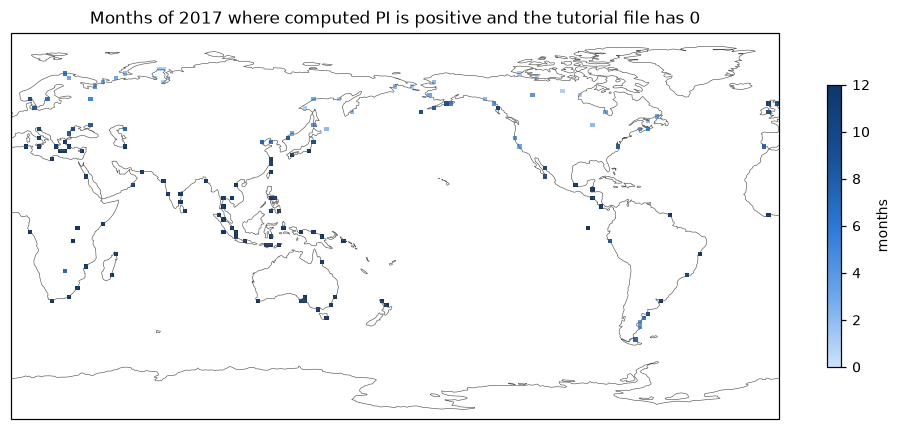

In [9]:
import cartopy.crs as ccrs

fig, ax = plt.subplots(
    figsize=(9, 4), subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)}
)
d = xr.open_dataset(store.path(f'{store.FORCING}/2017/PI_2017.nc'))
count = edge.sum(axis=0)
im = ax.pcolormesh(
    d['lon'],
    d['lat'],
    np.where(count > 0, count, np.nan),
    cmap=SEQ,
    vmin=0,
    vmax=12,
    transform=ccrs.PlateCarree(),
)
ax.coastlines(lw=0.4, color='#52514e')
ax.set_title('Months of 2017 where computed PI is positive and the tutorial file has 0')
fig.colorbar(im, ax=ax, shrink=0.7, label='months')
fig.tight_layout()

## Summary and open items

Our 2017 forcing reproduces the tutorial's files. The daily winds are means of the four 6-hourly
analyses (0.0004 m s⁻¹ rms, the size of rounding), and the monthly winds, humidity, all ten
covariances and all twelve months of Cholesky factors agree to rms at most 0.01% of each field's
spread. PI matches except at one cell, 39°N 0°E, where our mask treats the 0° meridian
differently. Where the tutorial's notebook code and its
published files disagree, on the orientation of the Cholesky factor and on PI next to land, we
follow the files.

Open:

- **Cholesky factor of the published run.** Following the files may depart from the run behind
  the published ERA5 tracks, if that run used the notebook's code as written. The tracks notebook
  tests this against the tracks' motion.
- **Other years.** Only 2017 has a reference. The other years come from the same code, and the
  genesis-index notebook checks their TCGI against the published track counts year by year.
- **CMIP6.** The same files from GCM fields, with the genesis fields bias-corrected toward the
  ERA5 1981–2010 climatology (Camargo et al. 2025, §4c), are not tested here.